In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt



In [2]:
df = pd.read_csv("global_programming_languages_dataset_2020_2026.csv")
print(df.head())

     language  year                                  creator  first_release  \
0      Python  2020                         Guido van Rossum           1991   
1  JavaScript  2020                             Brendan Eich           1995   
2        Java  2020                            James Gosling           1995   
3         SQL  2020  Donald D. Chamberlin & Raymond F. Boyce           1974   
4         C++  2020                        Bjarne Stroustrup           1985   

  typing_discipline                                           paradigm  \
0           Dynamic       Multi-paradigm (OOP, Functional, Procedural)   
1           Dynamic  Multi-paradigm (Event-driven, Functional, Prot...   
2            Static                                    Object-Oriented   
3            Static                                        Declarative   
4            Static          Multi-paradigm (OOP, Procedural, Generic)   

   github_repositories  stackoverflow_questions  tiobe_rank  pypl_rank  ...  \
0

In [3]:
# -------------------------------
df = df.drop_duplicates()
df = df.dropna(subset=["language","year"])

In [4]:
if "average_salary_usd" in df.columns:
    df["average_salary_usd"] = df["average_salary_usd"].fillna(df["average_salary_usd"].mean())

In [5]:
df["language"] = df["language"].str.strip().str.title()

In [8]:

print("\nInformación del dataset limpio:")
print(df.info())


Información del dataset limpio:
<class 'pandas.DataFrame'>
RangeIndex: 203 entries, 0 to 202
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   language                 203 non-null    str    
 1   year                     203 non-null    int64  
 2   creator                  203 non-null    str    
 3   first_release            203 non-null    int64  
 4   typing_discipline        203 non-null    str    
 5   paradigm                 203 non-null    str    
 6   github_repositories      203 non-null    int64  
 7   stackoverflow_questions  203 non-null    int64  
 8   tiobe_rank               203 non-null    int64  
 9   pypl_rank                203 non-null    int64  
 10  github_stars             203 non-null    int64  
 11  average_salary_usd       203 non-null    float64
 12  learning_difficulty      203 non-null    float64
 13  performance_score        203 non-null    float64
 14  ai_p

In [9]:
print("\nEstadísticas descriptivas:")
print(df.describe(include="all"))


Estadísticas descriptivas:
       language         year                       creator  first_release  \
count       203   203.000000                           203     203.000000   
unique       29          NaN                            28            NaN   
top      Python          NaN  Microsoft (Anders Hejlsberg)            NaN   
freq          7          NaN                            14            NaN   
mean        NaN  2023.000000                           NaN    1997.689655   
std         NaN     2.004944                           NaN      11.538881   
min         NaN  2020.000000                           NaN    1972.000000   
25%         NaN  2021.000000                           NaN    1990.000000   
50%         NaN  2023.000000                           NaN    1995.000000   
75%         NaN  2025.000000                           NaN    2009.000000   
max         NaN  2026.000000                           NaN    2014.000000   

       typing_discipline                       

In [7]:
subset = df[df["language"].isin(["Python","Java","C++","JavaScript"])]

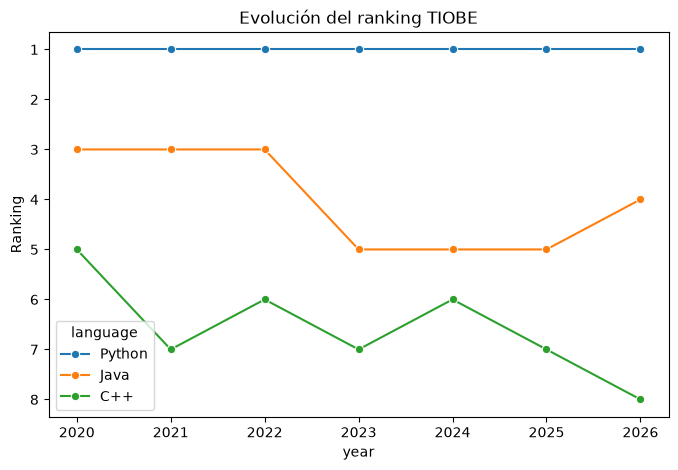

In [10]:
subset = df[df["language"].isin(["Python", "Java", "C++", "JavaScript"])]

plt.figure(figsize=(8,5))

sns.lineplot(
    data=subset,
    x="year",
    y="tiobe_rank",
    hue="language",
    marker="o"
)

plt.title("Evolución del ranking TIOBE")
plt.ylabel("Ranking")
plt.gca().invert_yaxis()  # 1 es mejor que 10
plt.show()

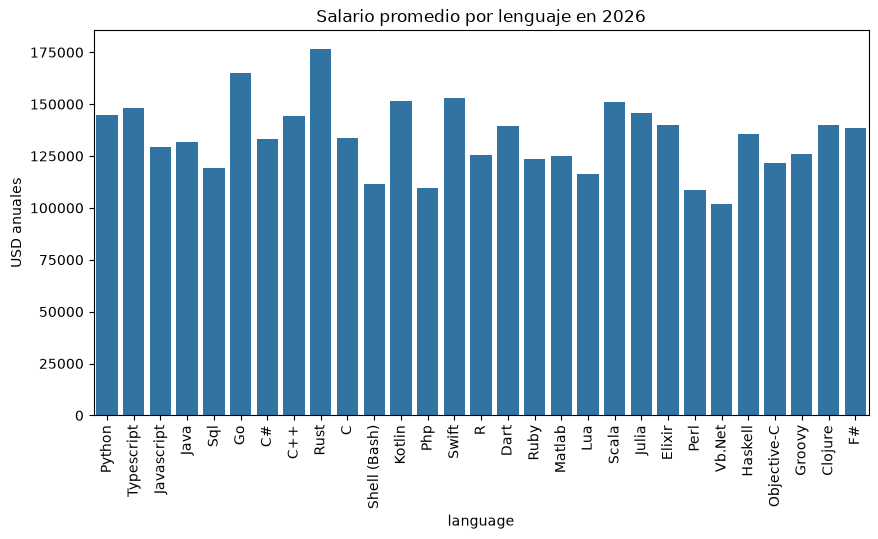

In [12]:
if "average_salary_usd" in df.columns:
    plt.figure(figsize=(10,5))
    sns.barplot(data=df[df["year"]==2026], x="language", y="average_salary_usd")
    plt.xticks(rotation=90)
    plt.title("Salario promedio por lenguaje en 2026")
    plt.ylabel("USD anuales")
    plt.show()

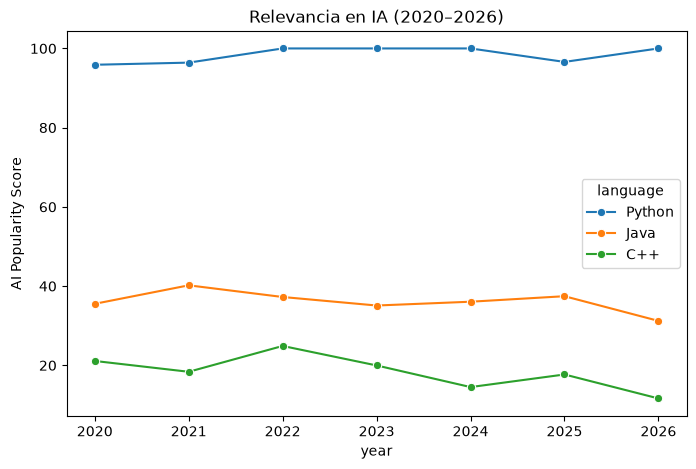

In [13]:
if "ai_popularity_score" in df.columns:
    plt.figure(figsize=(8,5))
    sns.lineplot(data=subset, x="year", y="ai_popularity_score", hue="language", marker="o")
    plt.title("Relevancia en IA (2020–2026)")
    plt.ylabel("AI Popularity Score")
    plt.show()

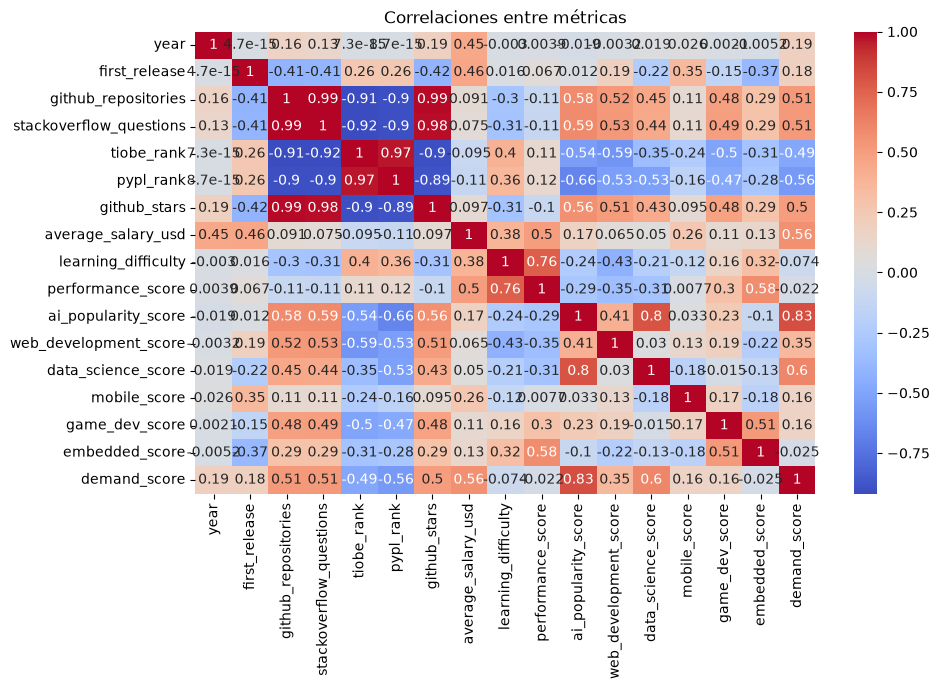

In [14]:
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Correlaciones entre métricas")
plt.show()